# 🔬 Research Assistant Agent Demo

This notebook demonstrates the multi-turn AI research agent built with **LangGraph**, **Google Gemini**, and **Tavily Search**. The agent decomposes research topics into sub-questions, retrieves information from multiple tools, evaluates its own output quality, and delivers comprehensive, cited answers.

## 1. Setup
First, make sure your `.env` file is set up with `GOOGLE_API_KEY` and `TAVILY_API_KEY`. The notebook will load these using `dotenv`.

In [1]:
import os
from dotenv import load_dotenv

# Load environment variables from .env file
load_dotenv()

# Verify API keys
if not os.getenv("GOOGLE_API_KEY") or not os.getenv("TAVILY_API_KEY"):
    print("⚠️ Please set GOOGLE_API_KEY and TAVILY_API_KEY in your .env file")
else:
    print("✅ API keys loaded successfully!")

✅ API keys loaded successfully!


## 2. Agent Architecture
The agent is implemented as a **LangGraph StateGraph**. We can view its architecture using the included `graph.png`.

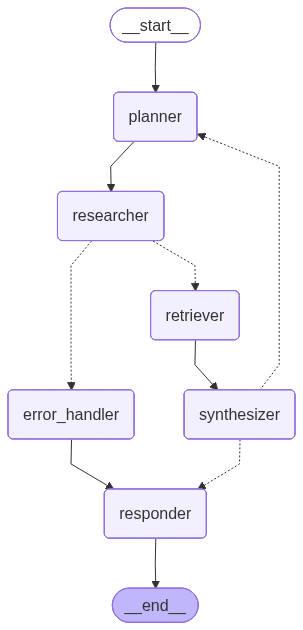

In [2]:
from IPython.display import Image
Image(filename="graph.png")

## 3. Running a Research Query
We will set up a function to run a query using the agent. This is similar to how the CLI loop works in `main.py`.

In [3]:
import uuid
from langchain_core.messages import HumanMessage
from graph import research_graph

def run_query(topic: str, thread_id: str):
    """
    Execute one research turn and print the final answer.
    """
    config = {"configurable": {"thread_id": thread_id}}
    
    # Initialize the state
    initial_state = {
        "messages": [HumanMessage(content=topic)],
        "topic": topic,
        "sub_questions": [],
        "search_results": [],
        "retrieved_docs": [],
        "sources": [],
        "synthesis": "",
        "final_answer": "",
        "turn_count": 0,
        "retry_count": 0,
        "error_message": "",
        "needs_more_research": False,
    }
    
    print(f"\n🔍 Running research for: '{topic}'...")
    print("This may take a minute as the agent searches and synthesizes information.")
    
    # Run the graph synchronously
    final_state = research_graph.invoke(initial_state, config=config)
    
    answer = final_state.get("final_answer", "No answer generated.")
    
    print("\n" + "═"*60)
    print("FINAL ANSWER")
    print("═"*60)
    print(answer)
    
    return final_state

Let's test the agent with an initial question about AI. We generate a unique `thread_id` to persist the conversation context.

In [4]:
# Generate a unique session ID
session_id = str(uuid.uuid4())

# Run the first query
topic = "What is retrieval-augmented generation (RAG)?"
state1 = run_query(topic, session_id)


🔍 Running research for: 'What is retrieval-augmented generation (RAG)?'...
This may take a minute as the agent searches and synthesizes information.

[Planner] Decomposing topic: 'What is retrieval-augmented generation (RAG)?' (turn 1)
[Planner] Generated 3 sub-questions:
  1. What is the core architecture and workflow of retrieval-augmented generation (RAG)?
  2. What are the primary benefits of using RAG compared to standard large language model fine-tuning?
  3. What are the common challenges and limitations of implementing RAG systems in production?

[Researcher] Running 3 Tavily search(es)...
  -> Searching: 'What is the core architecture and workflow of retrieval-augmented generation (RAG)?'


c:\Users\jingy\Downloads\suduAIPretask\tools\search_tools.py:33: LangChainDeprecationWarning: The class `TavilySearchResults` was deprecated in LangChain 0.3.25 and will be removed in 1.0. An updated version of the class exists in the `langchain-tavily package and should be used instead. To use it run `pip install -U `langchain-tavily` and import as `from `langchain_tavily import TavilySearch``.
  return TavilySearchResults(


    [+] Got 4 result(s).
  -> Searching: 'What are the primary benefits of using RAG compared to standard large language model fine-tuning?'
    [+] Got 4 result(s).
  -> Searching: 'What are the common challenges and limitations of implementing RAG systems in production?'
    [+] Got 4 result(s).
[Researcher] Total results collected: 12
[Router] retry_count=0 -> routing to retriever

[Retriever] Querying vector store with 4 query/queries...
[Retriever] Retrieved 3 unique document(s) from vector store.
  → Retrieval-Augmented Generation (RAG) (internal://docs/rag_overview)
  → Reinforcement Learning from Human Feedback (RLHF) (internal://docs/rlhf)
  → Introduction to Large Language Models (internal://docs/llm_intro)

[Synthesizer] Merging 12 web results + 3 local docs...
[Synthesizer] Built context from 15 unique source(s).
[Synthesizer] Sufficiency check → sufficient=True
[Router] needs_more_research=False, turn=1 -> responder

[Responder] Generating final answer for topic: 'What is 

## 4. Multi-turn Conversation
The LangGraph `MemorySaver` uses the `thread_id` to persist the conversation history. When we ask a follow-up question using the same `thread_id`, the agent knows the context of our previous question.

In [5]:
# Run a follow-up query using the same session_id
follow_up = "What are some popular frameworks used to build it?"
state2 = run_query(follow_up, session_id)


🔍 Running research for: 'What are some popular frameworks used to build it?'...
This may take a minute as the agent searches and synthesizes information.

[Planner] Decomposing topic: 'What are some popular frameworks used to build it?' (turn 1)
[Planner] Generated 3 sub-questions:
  1. What are the most popular open-source frameworks for building RAG applications?
  2. How do LangChain and LlamaIndex compare for implementing RAG pipelines?
  3. What are the key features of enterprise-grade RAG orchestration frameworks like Haystack or Flowise?

[Researcher] Running 3 Tavily search(es)...
  -> Searching: 'What are the most popular open-source frameworks for building RAG applications?'
    [+] Got 4 result(s).
  -> Searching: 'How do LangChain and LlamaIndex compare for implementing RAG pipelines?'
    [+] Got 4 result(s).
  -> Searching: 'What are the key features of enterprise-grade RAG orchestration frameworks like Haystack or Flowise?'
    [+] Got 4 result(s).
[Researcher] Total re

## 5. Inspecting the Internal State
Because we returned the `final_state` dictionary from the graph, we can inspect the agent's internal workings, such as the sub-questions it generated to break down the topic, and the sources it used.

In [6]:
print("Sub-questions generated for the follow-up query:")
for i, q in enumerate(state2.get("sub_questions", []), 1):
    print(f"{i}. {q}")

print("\nSources used:")
for s in state2.get("sources", []):
    print(f"- {s}")

Sub-questions generated for the follow-up query:
1. What are the most popular open-source frameworks for building RAG applications?
2. How do LangChain and LlamaIndex compare for implementing RAG pipelines?
3. What are the key features of enterprise-grade RAG orchestration frameworks like Haystack or Flowise?

Sources used:
- https://www.cake.ai/blog/best-open-source-agentic-rag
- https://www.firecrawl.dev/blog/best-open-source-rag-frameworks
- https://dev.to/rohan_sharma/top-10-open-source-rag-frameworks-you-need-3fhe
- https://aimultiple.com/retrieval-augmented-generation
- https://community.latenode.com/t/which-framework-should-i-choose-for-rag-development-langchain-vs-llamaindex/39107
- https://www.youtube.com/watch?v=T04AA_hhOsw
- https://coworker.ai/blog/langchain-vs-llamaindex
- https://blog.n8n.io/llamaindex-vs-langchain
- https://www.tredence.com/blog/top-rag-frameworks
- https://atlan.com/know/enterprise-rag-platforms-comparison
- https://www.xpay.sh/resources/agentic-framewo